# Projet Data Matching — A ↔ B

**M2 MIAGE · 数据准备与候选记录对生成**

1. **0. Environnement** — Python 依赖与本地环境。
2. **1. Data Exploration & Profiling** — A、B 的字段分布、缺失与格式异常。
3. **2. Standardisation** — A、B 独立完成格式标准化。
4. **3–4. 异常检测、纠错与验证** — 州代码纠错与处理前后核对。
5. **5. Pairing（TP1 第 3 节）** — 从最终的 A、B 生成去重的跨表候选对。

`rec_id` 是记录主键。候选对按 `(rec_id_A, rec_id_B)` 标识。

## 0. Environnement — 环境准备

### 0.1 Python 依赖检查

建议使用 VS Code 中同一个 `.venv` 内核。如果有依赖缺失，可运行：

```python
pip install pandas numpy matplotlib scikit-learn rapidfuzz sentence-transformers requests
```

In [1]:
# 检查核心依赖，避免出现“pip 安装成功但 Notebook 使用另一套 Python”的问题
import sys
import importlib.util
import importlib.metadata as metadata
import pandas as pd
from IPython.display import display

DEPENDENCIES = {
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
    "scikit-learn": "sklearn", "rapidfuzz": "rapidfuzz",
    "sentence-transformers": "sentence_transformers", "requests": "requests"
}
rows = []
for package, module in DEPENDENCIES.items():
    available = importlib.util.find_spec(module) is not None
    try:
        version = metadata.version(package) if available else "—"
    except metadata.PackageNotFoundError:
        version = "已安装（版本未知）" if available else "—"
    rows.append({"依赖": package, "状态": "OK" if available else "未安装", "版本": version})
print("当前 Python 解释器：", sys.executable)
display(pd.DataFrame(rows))
missing_packages = [r["依赖"] for r in rows if r["状态"] == "未安装"]
if missing_packages:
    install_command = "pip install " + " ".join(missing_packages)
    print("⚠️ 检测到缺失依赖：", ", ".join(missing_packages))
    print("请复制并运行下面的命令，然后重新运行本单元格：")
    print(install_command)
else:
    print("✅ 所有依赖均已安装。")

当前 Python 解释器： d:\CZY\Learn\MIAGE-M2-IPM\Data Matching\.venv\Scripts\python.exe


,依赖,状态,版本
0,pandas,OK,3.1.1
1,numpy,OK,2.5.4
2,matplotlib,OK,3.11.2
3,scikit-learn,OK,1.9.1
4,rapidfuzz,OK,3.14.6
5,sentence-transformers,OK,6.3.0
6,requests,OK,2.34.2


✅ 所有依赖均已安装。


### 0.2 本地路径和模型缓存

沿用的目录结构：

- Ollama 程序：`D:\AI\Ollama`
- Ollama 模型：`D:\AI\OllamaModels`
- Hugging Face：`D:\AI\HuggingFace`
- MiniLM 模型缓存：`D:\AI\HuggingFace\sentence-transformers`

**MiniLM 首次下载必须指向 D 盘。** 为此我们先设置环境变量，后面加载模型时也会显式传入 `cache_folder`。你只需要根据新电脑实际位置调整 `DATA_DIR`。

In [2]:
from pathlib import Path
import os
import platform

# ===== 主要配置：只需根据实际文件位置修改 DATA_DIR =====
DATA_DIR = Path(r"D:\CZY\Learn\MIAGE-M2-IPM\Data Matching\ex")

# 如果你把 Notebook 放在 A.csv / B.csv 旁边，可把上一行改为：
# DATA_DIR = Path.cwd()

# 输出保存在数据所在目录的同级文件夹，而不是写回原始 CSV
OUTPUT_DIR = DATA_DIR.parent / "projet_outputs"

# 所有 Hugging Face 模型均在 D 盘缓存
HF_CACHE = Path(r"D:\AI\HuggingFace")
ST_CACHE = HF_CACHE / "sentence-transformers"
os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["SENTENCE_TRANSFORMERS_HOME"] = str(ST_CACHE)
ST_CACHE.mkdir(parents=True, exist_ok=True)

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
PREPARE_MINILM = True  # True：本阶段就下载 / 加载；False：仅准备路径

# Qwen 是前期 TP 使用过的模型；本 Projet 后续计划研究 Jev，不依赖 Qwen
OLLAMA_MODEL = "qwen3.5:0.8b"
CHECK_OLLAMA = True  # 仅检查本地服务，不会重新下载 Qwen

# Jev 暂时只预留环境检查：不会发出在线 API 请求
CHECK_JEV_KEY = True

print("系统：", platform.platform())
print("A/B 数据目录：", DATA_DIR)
print("MiniLM 缓存目录：", ST_CACHE)
print("Ollama 模型目录（用户环境变量）：", os.environ.get("OLLAMA_MODELS", "未在当前进程设置"))
print("数据文件：", (DATA_DIR / "A.csv").exists(), (DATA_DIR / "B.csv").exists())

if platform.system() != "Windows":
    print("⚠️ 本配置面向 Windows + D 盘；其他系统需要修改 HF_CACHE。")
if platform.system() == "Windows" and not Path("D:/").exists():
    print("⚠️ 没有检测到 D 盘，请先修改缓存路径，再下载模型。")

系统： Windows-11-10.0.26200-SP0
A/B 数据目录： D:\CZY\Learn\MIAGE-M2-IPM\Data Matching\ex
MiniLM 缓存目录： D:\AI\HuggingFace\sentence-transformers
Ollama 模型目录（用户环境变量）： D:\AI\OllamaModels
数据文件： True True


### 0.3 Ollama / Jev 环境就绪检查（可选）

这里**不调用 Qwen、不调用 Jev，也不触发收费请求**：

- 如果 Ollama 服务正在运行，我们确认本地 API 是否能看到 `qwen3.5:0.8b`。
- Jev 未来将用于决策实验，此处只检查环境变量中是否存在访问密钥，**不会显示密钥内容**。正式接入时还需要核对账户权限和官方接口文档。
- 无论下面输出什么结果，**都不会阻碍接下来的 A/B Data Profiling**。

In [3]:
import json
from urllib.request import urlopen
from urllib.error import URLError

if CHECK_OLLAMA:
    try:
        with urlopen("http://127.0.0.1:11434/api/tags", timeout=3) as resp:
            tags = json.load(resp)
        model_names = [m.get("name", "") for m in tags.get("models", [])]
        print("Ollama 本地服务：已连接")
        print("本地可见模型：", model_names)
        print("TP 使用的 Qwen 0.8B：", "已找到" if OLLAMA_MODEL in model_names else "未在列表中")
    except (OSError, URLError, ValueError) as exc:
        print("Ollama 服务暂不可访问（不影响本阶段）：", type(exc).__name__)
        print("如果需要调用它，可在终端检查 Ollama 是否已启动；本 Projet 的 Jev 扩展并不依赖 Qwen。")

if CHECK_JEV_KEY:
    print("Jev 密钥：", "检测到 TYPESAFE_API_KEY（未调用）" if os.getenv("TYPESAFE_API_KEY") else "暂未配置（本阶段不需要）")

Ollama 服务暂不可访问（不影响本阶段）： URLError
如果需要调用它，可在终端检查 Ollama 是否已启动；本 Projet 的 Jev 扩展并不依赖 Qwen。
Jev 密钥： 暂未配置（本阶段不需要）


### 0.4 MiniLM 准备：自动下载到 D 盘（第一次运行）

MiniLM 是一个 **Encoder**，负责把文本转换成 384 维向量；它不是 Qwen，也不用通过 Ollama 下载。

- 如果 `ST_CACHE` 里没有模型，首次加载会从 Hugging Face 下载到 D 盘（需要网络）。
- 如果已经下载，会复用缓存，不需要重复下载。
- 这里仅编码一条测试文本，**不会提前计算 A/B 中所有记录的 Embedding**；后续 Pairing 阶段再考虑批量编码和向量缓存。
- 如果暂时只想做数据清洗，可把前面的 `PREPARE_MINILM` 改成 `False`。

In [4]:
encoder = None
MINILM_READY = False
if PREPARE_MINILM:
    try:
        from sentence_transformers import SentenceTransformer
        encoder = SentenceTransformer(
            EMB_MODEL,
            device="cpu",
            cache_folder=str(ST_CACHE)  # 明确指定 D 盘，避免下载到默认 C 盘缓存
        )
        sample_embedding = encoder.encode(["person name: alice; city: sydney"])
        print("MiniLM 已成功加载！")
        print("单条测试文本向量形状：", sample_embedding.shape)
        print("模型目录：", ST_CACHE)
        MINILM_READY = True
    except Exception as exc:
        print("⚠️ MiniLM 尚未加载成功，但可继续完成 Profiling 和 Standardisation。")
        print("错误类型：", type(exc).__name__, "|", str(exc)[:350])
        print("请检查 sentence-transformers 安装、网络连接与缓存路径。")
else:
    print("按照配置跳过 MiniLM 下载；路径已准备好。")

d:\CZY\Learn\MIAGE-M2-IPM\Data Matching\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1753.29it/s]


MiniLM 已成功加载！
单条测试文本向量形状： (1, 384)
模型目录： D:\AI\HuggingFace\sentence-transformers


## 1. Data Exploration & Profiling — 检查 A / B 的实际情况

### 1.1 读取、字段与样本

根据老师给的 CSV 示例，A 与 B 都应有 `rec_id` 和 10 个个人信息属性。这里保持所有字段为 `string`：邮编、生日、社保编号可能有前导零，不能先转成数值。

读取只做**最小必要清理**：列名、字段首尾空格和空字符串。此阶段不去除内部字符、不填缺失值、不更改姓名或地址。

`A_raw` / `B_raw` 是后续所有修改的原始对照基础。

In [5]:
import numpy as np
import pandas as pd

FIELDS = [
    "given_name", "surname", "street_number", "address_1", "address_2",
    "suburb", "postcode", "state", "date_of_birth", "soc_sec_id"
]
EXPECTED_COLUMNS = ["rec_id"] + FIELDS

def read_dataset(filename):
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(
            f"未找到 {path}\n请在 0.2 的配置单元格修改 DATA_DIR，指向 A.csv/B.csv 所在的文件夹。"
        )
    try:
        df = pd.read_csv(path, dtype=object, skipinitialspace=True, encoding="utf-8-sig")
    except UnicodeDecodeError:
        # 部分旧版澳大利亚数据可能采用 Windows 西文编码；出现此情况时保留提示
        print(f"⚠️ {filename} 不是 UTF-8，尝试使用 cp1252 解码。")
        df = pd.read_csv(path, dtype=object, skipinitialspace=True, encoding="cp1252")

    df.columns = df.columns.str.strip()
    if df.columns.duplicated().any():
        raise ValueError(f"{filename} 列名重复：{df.columns[df.columns.duplicated()].tolist()}")
    missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
    if missing:
        raise ValueError(f"{filename} 缺少必需字段：{missing}")
    extra = sorted(set(df.columns) - set(EXPECTED_COLUMNS))
    if extra:
        print(f"ℹ️ {filename} 额外字段（保留在 DataFrame 中）：{extra}")
    for col in df.columns:
        df[col] = df[col].str.strip().replace(r"^\s*$", np.nan, regex=True)
    return df

A_source = read_dataset("A.csv")
B_source = read_dataset("B.csv")
print(f"Dataset A: {len(A_source):,} 行 × {A_source.shape[1]} 列")
print(f"Dataset B: {len(B_source):,} 行 × {B_source.shape[1]} 列")
print(f"所有跨数据集可能的记录对：{len(A_source)*len(B_source):,}")
print("A/B 字段是否一致：", set(A_source.columns) == set(B_source.columns))
print("Dataset A 前 5 行：")
display(A_source.head(5))
print("Dataset B 前 5 行：")
display(B_source.head(5))

Dataset A: 5,000 行 × 11 列
Dataset B: 5,000 行 × 11 列
所有跨数据集可能的记录对：25,000,000
A/B 字段是否一致： True
Dataset A 前 5 行：


,rec_id,given_name,surname,street_number,address_1,address_2,suburb,postcode,state,date_of_birth,soc_sec_id
0,rec-1070-org,michaela,neumann,8,stanley street,miami,winston hills,4223,nsw,19151111,5304218
1,rec-1016-org,courtney,painter,12,pinkerton circuit,bega flats,richlands,4560,vic,19161214,4066625
2,rec-4405-org,charles,green,38,salkauskas crescent,kela,dapto,4566,nsw,19480930,4365168
3,rec-1288-org,vanessa,parr,905,macquoid place,broadbridge manor,south grafton,2135,sa,19951119,9239102
4,rec-3585-org,mikayla,malloney,37,randwick road,avalind,hoppers crossing,4552,vic,19860208,7207688


Dataset B 前 5 行：


,rec_id,given_name,surname,street_number,address_1,address_2,suburb,postcode,state,date_of_birth,soc_sec_id
0,rec-561-dup-0,elton,NaN,3,light setreet,pinehill,windermere,3212,vic,19651013,1551941
1,rec-2642-dup-0,mitchell,maxon,47,edkins street,lochaoair,north ryde,3355,nsw,19390212,8859999
2,rec-608-dup-0,NaN,white,72,lambrigg street,kelgoola,broadbeach waters,3159,vic,19620216,9731855
3,rec-3239-dup-0,elk i,menzies,1,lyster place,NaN,northwood,2585,vic,19980624,4970481
4,rec-2886-dup-0,NaN,garanggar,NaN,may maxwell crescent,springettst arcade,forest hill,2342,vic,19921016,1366884


### 1.2 数据质量概览

分别检查 A 和 B 的完整性、字段区分能力、重复记录和格式异常。

- **Missing rate / Completeness** 统计字段缺失情况，为选择 Blocking 字段提供依据。
- **Distinct values** 统计非缺失的不同取值，评估字段的区分能力。
- **Duplicate rows** 统计整行重复，以及忽略 `rec_id` 后的重复。
- **记录主键** 检查 `rec_id` 是否缺失，以及是否在 A、B 合并范围内唯一。
- **字段格式** 检查 4 位邮编、澳大利亚州和领地缩写、常见门牌号格式，以及能否按 `YYYYMMDD` 解析出生日期。

格式异常值需要复核。数据合成、录入错误或特殊业务情况都可能触发标记。

--- Dataset A ---
记录数： 5000
rec_id 空值： 0
rec_id 重复： 0
除 rec_id 外完全重复的记录： 0
整行完全重复： 0
--- Dataset B ---
记录数： 5000
rec_id 空值： 0
rec_id 重复： 0
除 rec_id 外完全重复的记录： 0
整行完全重复： 0
A、B 之间重复的 rec_id 数： 0


,dataset,field,missing_count,missing_pct,completeness_pct,distinct_values
0,A,given_name,112,2.24,97.76,770
1,A,surname,48,0.96,99.04,1827
2,A,street_number,158,3.16,96.84,450
3,A,address_1,98,1.96,98.04,2399
4,A,address_2,420,8.40,91.60,2575
5,A,suburb,55,1.10,98.90,1634
6,A,postcode,0,0.00,100.00,1419
7,A,state,50,1.00,99.00,8
8,A,date_of_birth,94,1.88,98.12,4588
9,A,soc_sec_id,0,0.00,100.00,5000


A 和 B 的缺失率对比：


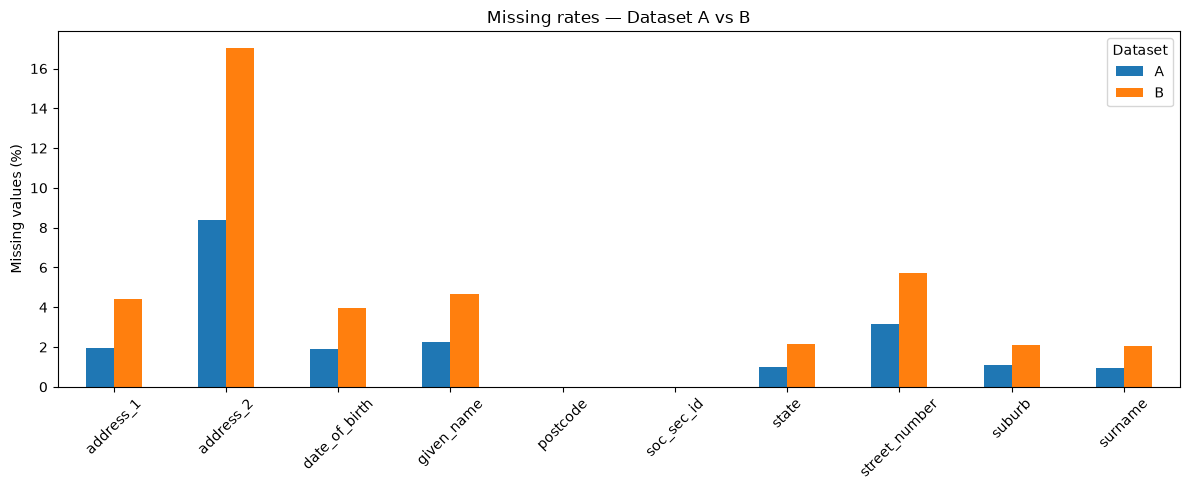

,dataset,check,count,share_pct
0,A,postcode_not_4_digits,0,0.00
1,A,invalid_YYYYMMDD_date,0,0.00
2,A,state_not_in_reference_list,0,0.00
3,A,unusual_street_number,0,0.00
4,B,postcode_not_4_digits,0,0.00
5,B,invalid_YYYYMMDD_date,64,1.28
6,B,state_not_in_reference_list,108,2.16
7,B,unusual_street_number,0,0.00


A 的部分异常样本（仅前 5 条）：
B 的部分异常样本（仅前 5 条）：
invalid_YYYYMMDD_date


,rec_id,date_of_birth
22,rec-3978-dup-0,19450493
125,rec-1270-dup-0,19960094
134,rec-4274-dup-0,19900270
177,rec-1399-dup-0,19105412
200,rec-299-dup-0,19399222


state_not_in_reference_list


,rec_id,state
36,rec-4618-dup-0,ni
81,rec-2713-dup-0,nws
109,rec-649-dup-0,nws
141,rec-2114-dup-0,aw
147,rec-654-dup-0,nse


In [6]:
import matplotlib.pyplot as plt


def dataset_overview(df, name):
    print(f"--- Dataset {name} ---")
    print("记录数：", len(df))
    print("rec_id 空值：", int(df["rec_id"].isna().sum()))
    print("rec_id 重复：", int(df["rec_id"].dropna().duplicated().sum()))
    print("除 rec_id 外完全重复的记录：", int(df.duplicated(subset=FIELDS).sum()))
    print("整行完全重复：", int(df.duplicated().sum()))
    return pd.DataFrame({
        "dataset": name,
        "field": FIELDS,
        "missing_count": [int(df[c].isna().sum()) for c in FIELDS],
        "missing_pct": [round(100 * df[c].isna().mean(), 2) for c in FIELDS],
        "completeness_pct": [round(100 * df[c].notna().mean(), 2) for c in FIELDS],
        "distinct_values": [int(df[c].nunique(dropna=True)) for c in FIELDS],
    })

profiling_A = dataset_overview(A_source, "A")
profiling_B = dataset_overview(B_source, "B")
shared_rec_ids = pd.Index(A_source["rec_id"].dropna()).intersection(
    B_source["rec_id"].dropna()
)
print("A、B 之间重复的 rec_id 数：", len(shared_rec_ids))
profiling = pd.concat([profiling_A, profiling_B], ignore_index=True)
display(profiling)

# 未经验证前，不应把普通记录中的重复视为错误而自行删除
print("A 和 B 的缺失率对比：")
missing_chart = profiling.pivot(index="field", columns="dataset", values="missing_pct")
ax = missing_chart.plot.bar(figsize=(12, 5), rot=45)
ax.set_ylabel("Missing values (%)")
ax.set_xlabel("")
ax.set_title("Missing rates — Dataset A vs B")
ax.legend(title="Dataset")
plt.tight_layout()
plt.show()

# 格式诊断只读取源数据，不会更改或删除任何记录
AU_STATES = {"NSW", "VIC", "QLD", "SA", "WA", "TAS", "ACT", "NT"}

FORMAT_CHECK_NAMES = {
    "postcode": "postcode_not_4_digits",
    "date_of_birth": "invalid_YYYYMMDD_date",
    "state": "state_not_in_reference_list",
    "street_number": "unusual_street_number",
}


def format_masks(df):
    postcode = df["postcode"].astype("string")
    dob = df["date_of_birth"].astype("string")
    state = df["state"].astype("string").str.upper()
    snum = df["street_number"].astype("string")

    bad_postcode = postcode.notna() & ~postcode.str.fullmatch(r"\d{4}").fillna(False)
    parsed_dates = pd.to_datetime(dob, format="%Y%m%d", errors="coerce")
    bad_date = dob.notna() & parsed_dates.isna()
    unknown_state = state.notna() & ~state.isin(AU_STATES)
    unusual_number = snum.notna() & ~snum.str.fullmatch(r"\d+[A-Za-z]?").fillna(False)

    return pd.DataFrame({
        "postcode": bad_postcode,
        "date_of_birth": bad_date,
        "state": unknown_state,
        "street_number": unusual_number,
    })


def analyze_formats(df, name):
    masks = format_masks(df)
    summary = pd.DataFrame({
        "dataset": name,
        "check": [FORMAT_CHECK_NAMES[field] for field in masks],
        "count": [int(mask.sum()) for _, mask in masks.items()],
        "share_pct": [round(100 * mask.mean(), 2) for _, mask in masks.items()],
    })
    examples = {
        FORMAT_CHECK_NAMES[field]: df.loc[mask, ["rec_id", field]].head(5)
        for field, mask in masks.items()
    }
    return summary, examples

quality_A, examples_A = analyze_formats(A_source, "A")
quality_B, examples_B = analyze_formats(B_source, "B")
quality_report = pd.concat([quality_A, quality_B], ignore_index=True)
display(quality_report)

print("A 的部分异常样本（仅前 5 条）：")
for check, sample in examples_A.items():
    if not sample.empty:
        print(check)
        display(sample)
print("B 的部分异常样本（仅前 5 条）：")
for check, sample in examples_B.items():
    if not sample.empty:
        print(check)
        display(sample)

## 2. 格式标准化

### 2.1 格式规则与缺失值约定

针对目前观察到的结构化姓名与地址数据，优先采取**保守、可追溯**的格式规则：

| 字段类型 | 标准化方式 | 为什么 |
|---|---|---|
| 姓名、街道、suburb、state | 去两端空格、统一大写、Unicode 兼容、标点转空格、合并多空格 | 消除格式差异，不猜测真实内容 |
| `street_number` | 同文本字段，**保留字母后缀**（例如 `12A`） | 门牌号不一定全是数字 |
| `postcode` | 仅在纯数字/空格/常见分隔符时去除分隔符，保留前导零 | 澳大利亚邮编通常 4 位 |
| `date_of_birth` | 将明确可识别的 `YYYY-MM-DD` / `YYYYMMDD` 转换为 `YYYYMMDD` | 统一日期形式；非法日期原样保留待复核 |
| `soc_sec_id` | 对数字型标识符仅去除常见分隔符，不做整数转换 | 不能丢失前导零 |
| 缺失值 | 空白和缺失标记统一为 `np.nan`（显示为 `NaN`） | 统一缺失值的表示，保留信息缺失的状态 |

空字符串、纯空格以及 `NULL`、`NONE`、`N/A`、`NA`、`NAN` 等标记均按缺失处理。采用 TP1 的处理方式，列以 `object` 类型保存文本和实际缺失值 `np.nan`。字符串操作在转换大小写时保留缺失状态。文本 `"NAN"` 会作为普通字符串参与比较，两条记录中的相同文本可能产生虚假的一致。

本节统一字段表示，结果保存为 `A_std`、`B_std`。州代码拼写纠错在第 3 节单独执行。姓名、地址的疑似拼写问题及非法生日保留现有内容，缺失值不补填。

In [7]:
import re
import unicodedata

# 格式标准化函数只处理当前值，不读取另一张表，也不推断拼写的正确答案。
MISSING_MARKERS = {"", "NULL", "NONE", "N/A", "NA", "NAN"}

def clean_missing(value):
    """先识别真实缺失值，再识别空白和缺失标记，统一返回 np.nan。"""
    if pd.isna(value):
        return np.nan
    t = str(value).strip()
    return np.nan if t.upper() in MISSING_MARKERS else t

def normalize_text(value):
    """统一大小写、Unicode、标点和空格，保留单个内部空格。"""
    value = clean_missing(value)
    if pd.isna(value):
        return np.nan
    s = unicodedata.normalize("NFKD", value)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = s.upper()
    s = re.sub(r"[^A-Z0-9\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s if s else np.nan

def normalize_numeric_identifier(value):
    """数字型标识符按文本处理，去除格式分隔符并保留前导零。"""
    value = clean_missing(value)
    if pd.isna(value):
        return np.nan
    s = str(value).strip()
    # 只对明显是数字+格式分隔符的输入移除空格、点、斜杠、连字符
    if re.fullmatch(r"[0-9\s./-]+", s):
        digits = re.sub(r"\D", "", s)
        return digits if digits else np.nan
    # 混有字母的异常值不自动删掉字母，防止伪造合法编号
    return normalize_text(s)

def normalize_birth_date(value):
    """只统一可解析的年月日格式，非法日期不猜测、不替换。"""
    s = clean_missing(value)
    if pd.isna(s):
        return np.nan
    # 只接受明确的年-月-日顺序，不猜测模糊日期
    if re.fullmatch(r"\d{4}[-/.]\d{1,2}[-/.]\d{1,2}", s):
        parts = re.split(r"[-/.]", s)
        digits = f"{parts[0]}{int(parts[1]):02d}{int(parts[2]):02d}"
    elif re.fullmatch(r"\d{8}", s):
        digits = s
    else:
        return str(value)
    parsed = pd.to_datetime(digits, format="%Y%m%d", errors="coerce")
    return digits if pd.notna(parsed) else str(value)

# 简短单元测试：提前确认不会删除前导零或编造缺失数据
assert normalize_text("  Élisabeth--Martin ") == "ELISABETH MARTIN"
assert normalize_numeric_identifier(" 0 123 ") == "0123"
assert normalize_birth_date("1998-03-02") == "19980302"
assert normalize_birth_date("1998-02-30") == "1998-02-30"
assert pd.isna(normalize_text("   "))
print("格式标准化函数检查通过。")

格式标准化函数检查通过。


### 2.2 对 A、B 分别执行格式标准化

数据按阶段独立保存，记录索引均为 `rec_id`：

| 变量 | 内容 |
|---|---|
| `A_raw`、`B_raw` | 完成最小 CSV 读取清理的原始对照 |
| `A_std`、`B_std` | 仅完成格式标准化的结果 |
| `A`、`B` | 第 3 节执行州代码纠错后的最终结果 |

`FIELDS` 包含 10 个业务字段，不含 `rec_id`。构建索引前检查 `rec_id` 非空，并在 A、B 合并范围内唯一。


In [ ]:
# 检查记录主键，再分别构建原始对照；主键不参与字段变换。
for name, source in (("A", A_source), ("B", B_source)):
    if source["rec_id"].isna().any():
        raise ValueError(f"Dataset {name} 有缺失 rec_id，请先检查，不能直接索引。")
    if source["rec_id"].duplicated().any():
        raise ValueError(f"Dataset {name} 有重复 rec_id，请先检查，不能直接索引。")

if A_source["rec_id"].isin(B_source["rec_id"]).any():
    raise ValueError("A 和 B 有相同的 rec_id，请先修正跨表重复的记录编号。")

A_raw = A_source.set_index("rec_id", drop=True).copy()
B_raw = B_source.set_index("rec_id", drop=True).copy()

TEXT_COLUMNS = ["given_name", "surname", "street_number", "address_1", "address_2", "suburb", "state"]
NUMERIC_COLUMNS = ["postcode", "soc_sec_id"]

def standardize_dataset(df):
    """只统一单个数据集的格式，返回副本，保留原始对照。"""
    out = df.copy(deep=True)
    for col in TEXT_COLUMNS:
        out[col] = out[col].map(normalize_text).astype(object)
    for col in NUMERIC_COLUMNS:
        out[col] = out[col].map(normalize_numeric_identifier).astype(object)
    out["date_of_birth"] = out["date_of_birth"].map(normalize_birth_date).astype(object)
    # rec_id 是索引，不能参与属性变换
    return out

A_std = standardize_dataset(A_raw)
B_std = standardize_dataset(B_raw)

assert len(A_std) == len(A_raw) and len(B_std) == len(B_raw), "标准化不应改变行数"
assert A_std.index.equals(A_raw.index) and B_std.index.equals(B_raw.index), "标准化不应改变记录 ID 或其顺序"
assert A_std.columns.equals(A_raw.columns) and B_std.columns.equals(B_raw.columns), "标准化不应改变字段集合"

print("格式标准化完成。A：", A_std.shape, "| B：", B_std.shape)

## 3. 异常检测与纠错

### 3.1 州代码参考与纠错规则

**澳大利亚州代码适用范围的合理推断：**本地 A、B 与公开 FEBRL4 数据逐字段一致；FEBRL4 的生成说明指出，示例数据由生成器及配套频率表产生。配套州频率表仅包含 `ACT、NSW、NT、QLD、SA、TAS、VIC、WA`，与 Australia Post 定义的州／领地代码一致。因此，本项目根据数据来源和生成配置，将 `state` 的预期取值范围限定为这 8 个澳大利亚代码。该判断针对当前合成数据，不能据此证明每条地址在现实中真实存在。

来源：[FEBRL4 生成说明](https://raw.githubusercontent.com/J535D165/FEBRL-fork-v0.4.2/master/dsgen/README.txt)、[生成器州频率表](https://raw.githubusercontent.com/J535D165/FEBRL-fork-v0.4.2/master/dsgen/data/state-freq.csv)、[Australia Post 州代码定义](https://developers.auspost.com.au/content/apis/shipping-and-tracking/partials/request-address-intl.html)。

**异常检测**判断当前州值是否在参考表中；**纠错属于合理推断**，根据字符差异提出并选择候选。这一步与第 2 节的格式标准化分开统计。

[原作者的生成器说明](https://users.cecs.anu.edu.au/~Peter.Christen/Febrl/febrl-0.3/febrldoc-0.3/node70.html)指出，数据生成过程会引入字符插入、删除、替换和交换等扰动。Damerau–Levenshtein 距离覆盖这些操作，将插入、删除、替换一个字符，以及交换两个相邻字符，各计为一次编辑。

**选择“距离为 1 且候选唯一”的理由：**一次字符编辑就能把异常值变为合法代码，符合小幅录入错误的假设；最近候选唯一，表示参考表中没有同等接近的其他代码。例如 `NWS → NSW` 只需交换相邻字母，且 `NSW` 是唯一最近候选，因此按最小改动原则进行替换。对于 `AS`，`SA` 和 `TAS` 的距离都为 1，依据不足以选择其中一个，故保留原值。

| 情况 | 处理规则 |
|---|---|
| 缺失值 | 保持 `np.nan` |
| 已是合法州代码 | 保持原值 |
| 最小距离为 1，且最近候选唯一 | 按合理推断替换为该候选 |
| 最近候选不唯一 | 保留原值，记录候选和歧义原因 |
| 最小距离大于 1 | 保留原值，记录距离超出阈值 |

编辑距离衡量字符差异，不代表候选为真实州的概率；唯一候选也不能视为已核实的真实值。原值、候选、距离、处理后值和处理结果保存在 `state_correction_log`，可按记录回查。

A、B 独立使用相同规则和固定参考表。生日、姓名、地址及缺失值不在本节的自动修复范围内。


In [ ]:
from rapidfuzz.distance import DamerauLevenshtein

STATE_MAX_DISTANCE = 1
STATE_LOG_COLUMNS = [
    "数据集", "rec_id", "原州代码", "处理后州代码", "最近距离", "候选州代码", "处理结果"
]


def nearest_state_codes(value):
    """对非空、已标准化的州值计算最近代码，并保留所有并列候选。"""
    distances = {
        code: DamerauLevenshtein.distance(value, code)
        for code in sorted(AU_STATES)
    }
    nearest_distance = min(distances.values())
    candidates = tuple(code for code, distance in distances.items() if distance == nearest_distance)
    return nearest_distance, candidates


def correct_state_codes(standardized, dataset_name):
    """只修复距离为 1 且候选唯一的非法州代码，返回结果副本与处理明细。"""
    corrected = standardized.copy(deep=True)
    rows = []

    # 缺失值和合法代码不进入纠错，避免补值或改动原本合法的内容。
    invalid_state = standardized["state"].notna() & ~standardized["state"].isin(AU_STATES)
    for rec_id, value in standardized.loc[invalid_state, "state"].items():
        distance, candidates = nearest_state_codes(value)
        replacement = value
        if distance > STATE_MAX_DISTANCE:
            status = "保留：距离超过阈值"
        elif len(candidates) != 1:
            status = "保留：候选不唯一"
        else:
            replacement = candidates[0]
            status = "已按规则纠正"
            corrected.at[rec_id, "state"] = replacement

        # 保留全部异常值的决策依据；明细按需查看，不直接输出长表。
        rows.append({
            "数据集": dataset_name,
            "rec_id": rec_id,
            "原州代码": value,
            "处理后州代码": replacement,
            "最近距离": distance,
            "候选州代码": " / ".join(candidates),
            "处理结果": status,
        })

    log = pd.DataFrame(rows, columns=STATE_LOG_COLUMNS).astype({"最近距离": "int64"})
    return corrected, log


### 3.2 对 A、B 分别执行州代码纠错

以 `A_std`、`B_std` 为输入，生成 `A`、`B`，并保留标准化结果用于对照。纠错只允许改变 `state` 的非缺失异常值，不改变记录数、索引、其他字段或缺失位置。


In [ ]:
A, state_log_A = correct_state_codes(A_std, "A")
B, state_log_B = correct_state_codes(B_std, "B")
state_correction_log = pd.concat([state_log_A, state_log_B], ignore_index=True)

# 阶段边界检查：州代码纠错不能改变其他字段，也不能新增或填补缺失值。
for standardized, corrected in ((A_std, A), (B_std, B)):
    assert standardized.index.equals(corrected.index), "纠错不应改变记录数、ID 或顺序"
    assert standardized.columns.equals(corrected.columns), "纠错不应改变字段集合"
    assert standardized.drop(columns="state").equals(corrected.drop(columns="state")), "纠错只能修改州代码"
    assert standardized.isna().equals(corrected.isna()), "纠错不应改变缺失位置"

state_status = []
for dataset_name, log in (("A", state_log_A), ("B", state_log_B)):
    fixed_count = int(log["处理结果"].eq("已按规则纠正").sum())
    remaining_count = len(log) - fixed_count
    state_status.append(f"{dataset_name} 纠正 {fixed_count} 个，保留异常 {remaining_count} 个")
print("州代码纠错完成：" + "；".join(state_status) + "。")


州代码纠错完成：A 纠正 0 个，保留异常 0 个；B 纠正 103 个，保留异常 5 个。


## 4. 处理效果验证

汇总表按单元格分别统计两个阶段：**格式改动数**比较原始对照与格式标准化结果；**纠错数**比较格式标准化结果与州代码纠错结果。同一个值可能在两个阶段各发生一次变化，两列不能相加当作不同单元格的总数。

**原文未填写**统计原始对照中的空白和缺失标记，统一保存为 `np.nan`。**已填写但异常**统计处理后仍未通过现有字段校验的非空原值，以及原有内容被处理成缺失值的情况。

现有校验覆盖邮编位数、生日的日历合法性、州代码范围和门牌号格式；姓名和地址的拼写、内部空格及地理一致性尚不在此统计范围内。

每个数据集最多展示 3 条记录，按处理前、处理后对照全部业务字段；优先覆盖未解决的异常和州代码纠错示例。完整州代码处理明细保存在 `state_correction_log`。


In [ ]:
def compare_before_after(raw, cleaned, name):
    rows = []
    for col in FIELDS:
        old = raw[col]
        new = cleaned[col]
        # 两侧都缺失表示处理没有变化；这里只统计改动，不参与记录配对。
        changed = old.ne(new).fillna(True) & ~(old.isna() & new.isna())
        rows.append({
            "dataset": name, "field": col,
            "changed_rows": int(changed.sum()),
            "changed_pct": round(100 * changed.mean(), 2),
            "missing_before": int(raw[col].isna().sum()),
            "missing_after": int(cleaned[col].isna().sum()),
            "unique_before": int(raw[col].nunique(dropna=True)),
            "unique_after": int(cleaned[col].nunique(dropna=True)),
        })
    return pd.DataFrame(rows)

# 分开衡量格式标准化和州代码纠错，避免将推断修改混入格式改动。
changes_A = compare_before_after(A_raw, A_std, "A")
changes_B = compare_before_after(B_raw, B_std, "B")
corrections_A = compare_before_after(A_std, A, "A")
corrections_B = compare_before_after(B_std, B, "B")
change_report = pd.concat([changes_A, changes_B], ignore_index=True)
correction_report = pd.concat([corrections_A, corrections_B], ignore_index=True)

def review_field_quality(raw, cleaned):
    originally_missing = raw[FIELDS].apply(lambda column: column.map(clean_missing).isna())
    originally_filled = ~originally_missing
    after_issues = format_masks(cleaned).reindex(columns=FIELDS, fill_value=False) | cleaned[FIELDS].isna()
    after_review = originally_filled & after_issues
    counts = pd.DataFrame({
        "原文未填写": originally_missing.sum(),
        "已填写但异常": after_review.sum(),
    }, dtype="int64")
    return counts, after_review


field_counts_A, after_review_A = review_field_quality(A_raw, A)
field_counts_B, after_review_B = review_field_quality(B_raw, B)
field_quality = pd.concat({"A": field_counts_A, "B": field_counts_B}, axis=1)
field_quality.loc["合计"] = field_quality.sum()

# 对最终结果复用同一套字段校验，统计尚未解决的异常。
quality_A_clean, _ = analyze_formats(A.reset_index(), "A_final")
quality_B_clean, _ = analyze_formats(B.reset_index(), "B_final")
quality_after = pd.concat([quality_A_clean, quality_B_clean], ignore_index=True)

summary_by_dataset = {}
for dataset, changes, corrections in (("A", changes_A, corrections_A), ("B", changes_B, corrections_B)):
    changed = changes.set_index("field")["changed_rows"]
    changed.loc["合计"] = changed.sum()
    corrected_count = corrections.set_index("field")["changed_rows"]
    corrected_count.loc["合计"] = corrected_count.sum()
    counts = field_quality[dataset]
    summary_by_dataset[dataset] = pd.DataFrame({
        "格式改动数": changed,
        "纠错数": corrected_count,
        "原文未填写": counts["原文未填写"],
        "已填写但异常": counts["已填写但异常"],
    })
cleaning_summary = pd.concat(summary_by_dataset, axis=1)
print('按单元格计数：格式改动数与纠错数分别统计；原文未填写保持为 np.nan；已填写但异常仅反映现有校验规则。')
display(cleaning_summary)

preview_size = 3
versions = {}
for dataset, raw, cleaned, after_review in (
    ("A", A_raw, A, after_review_A),
    ("B", B_raw, B, after_review_B),
):
    ids_by_field = [
        after_review.index[after_review[field]][:preview_size] for field in FIELDS
    ]
    # 先覆盖各类剩余异常，再补一个州代码已纠正的例子，总数仍限制为 3 条。
    sample_candidates = [ids[0] for ids in ids_by_field if not ids.empty]
    corrected_ids = state_correction_log.loc[
        state_correction_log["数据集"].eq(dataset)
        & state_correction_log["处理结果"].eq("已按规则纠正"), "rec_id"
    ]
    sample_candidates.extend(corrected_ids.head(1))
    sample_candidates.extend(rec_id for ids in ids_by_field for rec_id in ids)
    sample_candidates.extend(raw.index[:preview_size])
    sample_ids = list(dict.fromkeys(sample_candidates))[:preview_size]
    before = raw.loc[sample_ids, FIELDS]
    after = cleaned.loc[sample_ids, FIELDS].copy()
    after["异常字段"] = [
        ", ".join(field for field, flagged in zip(FIELDS, flags) if flagged) or "—"
        for flags in after_review.loc[sample_ids, FIELDS].to_numpy()
    ]

    versions[(dataset, "处理前")] = before
    versions[(dataset, "处理后")] = after

cleaning_preview = pd.concat(versions, names=["数据集", "阶段", "rec_id"])
display(cleaning_preview.fillna({"异常字段": "—"}))

按单元格计数：格式改动数与纠错数分别统计；原文未填写保持为 np.nan；已填写但异常仅反映现有校验规则。


A                       B                  
               格式改动数 纠错数 原文未填写 已填写但异常  格式改动数  纠错数 原文未填写 已填写但异常
given_name      4888   0   112      0   4766    0   234      0
surname         4952   0    48      0   4898    0   102      0
street_number      0   0   158      0      0    0   287      0
address_1       4902   0    98      0   4780    0   220      0
address_2       4580   0   420      0   4149    0   851      0
suburb          4945   0    55      0   4894    0   106      0
postcode           0   0     0      0      0    0     0      0
state           4950   0    50      0   4893  103   107      5
date_of_birth      0   0    94      0      0    0   199     64
soc_sec_id         0   0     0      0      0    0     0      0
合计             29217   0  1035      0  28380  103  2106     69

given_name   surname  ... soc_sec_id           异常字段
数据集 阶段  rec_id                               ...                          
A   处理前 rec-1070-org     michaela   neumann  ...    5304218              —
        rec-1016-org     courtney   painter  ...    4066625              —
        rec-4405-org      charles     green  ...    4365168              —
    处理后 rec-1070-org     MICHAELA   NEUMANN  ...    5304218              —
        rec-1016-org     COURTNEY   PAINTER  ...    4066625              —
        rec-4405-org      CHARLES     GREEN  ...    4365168              —
B   处理前 rec-4955-dup-0     callum    hauser  ...    3757652              —
        rec-3978-dup-0        NaN     babic  ...    3346822              —
        rec-4618-dup-0      chloe  musoilno  ...    7147784              —
    处理后 rec-4955-dup-0     CALLUM    HAUSER  ...    3757652          state
        rec-3978-dup-0        NaN     BABIC  ...    3346822  date_of_birth
        rec-4618-dup-0      CHLOE  MUSOILNO  ...    7147784              —

[12 rows x 11 columns]

## 5. Pairing — 候选记录对生成（TP1 第 3 节）

A、B 的全量组合为 5,000 × 5,000 = 25,000,000 对。五轮规则分别作用于完整的 A、B，每轮跳过本轮键缺失的记录，最终取并集。

| 轮次 | 字段 | 入选条件 |
|---|---|---|
| 1 | `soc_sec_id` | 社保号完全相同 |
| 2 | `date_of_birth` | 两侧生日均有效且相同 |
| 3 | `postcode` | 邮编完全相同 |
| 4 | `surname` | 姓氏排序邻域，窗口为 5 |
| 5 | `given_name` | 名字排序邻域，窗口为 5；排除两侧州代码均合法且不一致的候选 |

每个姓名窗口以 A、B 合并后的非空不同取值排序为准，包含同值及前后各两个不同值。第 5 轮在生成名字邻域后检查州：任一侧州缺失或异常时保留该名字候选。前四轮选中的记录对始终保留。

In [10]:
def block_pairs(left_key, right_key):
    left = left_key.dropna().rename("key").rename_axis("rec_id_A").reset_index()
    right = right_key.dropna().rename("key").rename_axis("rec_id_B").reset_index()
    hits = left.merge(right, on="key", how="inner", sort=False)
    return pd.MultiIndex.from_frame(hits[["rec_id_A", "rec_id_B"]])


def sorted_neighbourhood_pairs(left_key, right_key, window=5):
    if window < 1 or window % 2 == 0:
        raise ValueError("排序邻域窗口必须为正奇数。")
    values = pd.Index(pd.concat([left_key, right_key]).dropna().unique()).sort_values()
    ranks = pd.Series(np.arange(len(values)), index=values)
    left_ranks = left_key.dropna().map(ranks)
    right_ranks = right_key.dropna().map(ranks)
    radius = window // 2
    blocks = [block_pairs(left_ranks, right_ranks + offset)
              for offset in range(-radius, radius + 1)]
    return blocks[0].append(blocks[1:])

In [11]:
def valid_birth_key(dates):
    digits = dates.where(dates.str.fullmatch(r"[0-9]{8}", na=False))
    return pd.to_datetime(digits, format="%Y%m%d", errors="coerce")


given_pairs = sorted_neighbourhood_pairs(A["given_name"], B["given_name"])
state_a = given_pairs.get_level_values("rec_id_A").map(A["state"])
state_b = given_pairs.get_level_values("rec_id_B").map(B["state"])
state_conflict = state_a.isin(AU_STATES) & state_b.isin(AU_STATES) & (state_a != state_b)

pairing_passes = {
    "社保号精确分块": block_pairs(A["soc_sec_id"], B["soc_sec_id"]),
    "有效生日精确分块": block_pairs(valid_birth_key(A["date_of_birth"]), valid_birth_key(B["date_of_birth"])),
    "邮编精确分块": block_pairs(A["postcode"], B["postcode"]),
    "姓氏排序邻域": sorted_neighbourhood_pairs(A["surname"], B["surname"]),
    "名字排序邻域（州过滤后）": given_pairs[~state_conflict],
}

In [12]:
full_pair_count = len(A) * len(B)
candidates = pd.MultiIndex.from_arrays([[], []], names=["rec_id_A", "rec_id_B"])
pairing_rows = []
for rule, pairs in pairing_passes.items():
    previous_count = len(candidates)
    candidates = candidates.union(pairs, sort=False)
    pairing_rows.append({
        "规则": rule,
        "本轮候选数": len(pairs),
        "本轮新增数": len(candidates) - previous_count,
        "累计候选数": len(candidates),
    })

pairing_summary = pd.DataFrame(pairing_rows).set_index("规则")
display(pairing_summary)
reduction_ratio = 1 - len(candidates) / full_pair_count
removed_from_union = len(given_pairs[state_conflict].difference(candidates, sort=False))
print(f"全量 {full_pair_count:,} 对，五轮并集 {len(candidates):,} 对，比较量减少 {reduction_ratio:.4%}。")
print(f"名字轮州过滤：{len(given_pairs):,} → {len(pairing_passes['名字排序邻域（州过滤后）']):,} 对。")
print(f"相对于五轮都不限州，最终并集减少 {removed_from_union:,} 对。")

,本轮候选数,本轮新增数,累计候选数
规则,,,
社保号精确分块,4561,4561,4561
有效生日精确分块,5107,1036,5597
邮编精确分块,28609,24424,30021
姓氏排序邻域,111761,107655,137676
名字排序邻域（州过滤后）,32484,28689,166365


全量 25,000,000 对，五轮并集 166,365 对，比较量减少 99.3345%。
名字轮州过滤：115,906 → 32,484 对。
相对于五轮都不限州，最终并集减少 82,925 对。


`candidates` 保存去重后的 A↔B 候选对。本轮新增数按表中顺序计算。比较量减少率为 1 − 候选并集数 / 全量对数；计算真实匹配的保留比例还需要独立确认的 A↔B 匹配标签。